# Adidas US Sales: Exploratory Data Analysis

Exploratory analysis of Adidas sales through six US retailers in 2020-2021: 9,648 records of units,
price, sales and operating profit by retailer, state, product and sales channel.

The raw file has a serious error: in 40% of rows, total sales is exactly ten times price x units.
Section 2 finds it, corrects it, and shows how much it would have distorted the results.

**Contents**
1. Load and tidy the raw Excel file
2. Data checks, including the 10x sales error
3. What the analysis covers (2020 coverage gap)
4. Sales over time
5. Products
6. Retailers and sales channels
7. Regions and states
8. Pricing by channel
9. Summary of findings

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", "{:,.2f}".format)

# chart settings
BLUE = "#2a78d6"
INK, MUTED, GRID = "black", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False,
})
millions = mtick.FuncFormatter(lambda x, _: f"${x / 1e6:,.0f}M")
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Load and tidy

The sheet opens with a title block: four blank or title rows and an empty first column. The real
header is on the fifth row.

In [2]:
raw = pd.read_excel("data/Adidas US Sales Datasets.xlsx", header=4)
raw = raw.drop(columns=raw.columns[0])          # empty first column
raw.columns = (raw.columns.str.strip().str.lower()
               .str.replace(" ", "_").str.replace("_per_", "_"))
raw.info()
raw.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9648 entries, 0 to 9647
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   retailer          9648 non-null   object        
 1   retailer_id       9648 non-null   int64         
 2   invoice_date      9648 non-null   datetime64[ns]
 3   region            9648 non-null   object        
 4   state             9648 non-null   object        
 5   city              9648 non-null   object        
 6   product           9648 non-null   object        
 7   price_unit        9648 non-null   float64       
 8   units_sold        9648 non-null   int64         
 9   total_sales       9648 non-null   float64       
 10  operating_profit  9648 non-null   float64       
 11  operating_margin  9648 non-null   float64       
 12  sales_method      9648 non-null   object        
dtypes: datetime64[ns](1), float64(4), int64(2), object(6)
memory usage: 980.0+ KB


,retailer,retailer_id,invoice_date,region,state,city,product,price_unit,units_sold,total_sales,operating_profit,operating_margin,sales_method
0,Foot Locker,1185732,2020-01-01,Northeast,New York,New York,Men's Street Footwear,50.00,1200,"600,000.00","300,000.00",0.50,In-store
1,Foot Locker,1185732,2020-01-02,Northeast,New York,New York,Men's Athletic Footwear,50.00,1000,"500,000.00","150,000.00",0.30,In-store
2,Foot Locker,1185732,2020-01-03,Northeast,New York,New York,Women's Street Footwear,40.00,1000,"400,000.00","140,000.00",0.35,In-store
3,Foot Locker,1185732,2020-01-04,Northeast,New York,New York,Women's Athletic Footwear,45.00,850,"382,500.00","133,875.00",0.35,In-store
4,Foot Locker,1185732,2020-01-05,Northeast,New York,New York,Men's Apparel,60.00,900,"540,000.00","162,000.00",0.30,In-store


## 2. Data checks

In [3]:
print("rows:", len(raw))
print("missing values:", raw.isna().sum().sum())
print("duplicate rows:", raw.duplicated().sum())
print("date range:", raw.invoice_date.min().date(), "to", raw.invoice_date.max().date())
for col in ["retailer", "region", "product", "sales_method"]:
    print(f"{col}: {raw[col].nunique()} values")

rows: 9648
missing values: 0
duplicate rows: 0
date range: 2020-01-01 to 2021-12-31
retailer: 6 values
region: 5 values
product: 6 values
sales_method: 3 values


### The 10x sales error

Total sales should equal price per unit x units sold. Comparing the two shows only two ratios in
the whole file: 1 and exactly 10.

In [4]:
calc = raw.price_unit * raw.units_sold
ratio = (raw.total_sales / calc).round(4)
ratio.value_counts(dropna=False)

1.00     5758
10.00    3886
NaN         4
Name: count, dtype: int64

In [5]:
inflated = ratio == 10
print(f"rows with sales = 10 x price x units: {inflated.sum():,} ({inflated.mean():.0%})")
pd.crosstab(raw.sales_method, inflated, margins=True)

rows with sales = 10 x price x units: 3,886 (40%)


col_0,False,True,All
sales_method,,,
In-store,0,1740,1740
Online,3888,1001,4889
Outlet,1874,1145,3019
All,5762,3886,9648


Every in-store row and about a third of online and outlet rows are affected. Unit counts on the
affected rows are in the same range as on the correct ones, so the error is in `total_sales`, not
in `units_sold`.

**Fix:** rebuild sales as price x units, and rebuild operating profit as sales x operating margin.
The margin column is consistent with the reported profit on every row, so it carries over. The
four rows with zero units sold are kept; they contribute nothing.

In [6]:
print("operating margin consistent with reported profit:",
      ((raw.operating_profit / raw.total_sales - raw.operating_margin).abs() < 1e-9)[raw.total_sales > 0].all())

df = raw.copy()
df["sales"] = df.price_unit * df.units_sold
df["profit"] = df.sales * df.operating_margin
df["year"] = df.invoice_date.dt.year
df["month"] = df.invoice_date.dt.to_period("M")

effect = pd.DataFrame({
    "as reported": [raw.total_sales.sum(), raw.operating_profit.sum()],
    "corrected": [df.sales.sum(), df.profit.sum()],
}, index=["sales", "operating profit"])
effect["reported / corrected"] = effect["as reported"] / effect["corrected"]
effect

operating margin consistent with reported profit: True


,as reported,corrected,reported / corrected
sales,"899,902,125.00","120,166,650.00",7.49
operating profit,"332,134,761.45","47,224,967.70",7.03


In [7]:
by_method = pd.DataFrame({
    "reported": raw.groupby("sales_method").total_sales.sum(),
    "corrected": df.groupby("sales_method").sales.sum(),
})
(by_method / by_method.sum()).style.format("{:.1%}")

,reported,corrected
sales_method,,
In-store,39.6%,29.7%
Online,27.5%,37.4%
Outlet,32.8%,32.9%


Left uncorrected, the error overstates total sales 7.5-fold ($900M reported against $120M) and
turns the channel ranking upside down: in-store looks like the biggest channel (40% of reported
sales) when it is actually the smallest (30%).

## 3. What the analysis covers

2020 is only partly covered: Amazon has no 2020 records at all, and the other retailers have far
fewer than in 2021. Comparing the two years would mostly measure the change in coverage, so the
rest of the analysis uses **2021, the one complete year**.

In [8]:
pd.crosstab(df.retailer, df.year, margins=True)

year,2020,2021,All
retailer,,,
Amazon,0,949,949
Foot Locker,337,2300,2637
Kohl's,8,1022,1030
Sports Direct,106,1926,2032
Walmart,216,410,626
West Gear,635,1739,2374
All,1302,8346,9648


In [9]:
d21 = df[df.year == 2021].copy()
print(f"2021: {len(d21):,} records, sales ${d21.sales.sum() / 1e6:,.1f}M, "
      f"operating profit ${d21.profit.sum() / 1e6:,.1f}M, "
      f"margin {d21.profit.sum() / d21.sales.sum():.1%}, "
      f"units {d21.units_sold.sum():,}")


def summary(by):
    g = d21.groupby(by).agg(sales=("sales", "sum"), profit=("profit", "sum"),
                            units=("units_sold", "sum"))
    g["share"] = g.sales / g.sales.sum()
    g["margin"] = g.profit / g.sales
    g["avg_price"] = g.sales / g.units
    return g.sort_values("sales", ascending=False)

2021: 8,346 records, sales $95.9M, operating profit $38.2M, margin 39.8%, units 2,016,512


## 4. Sales over time (2021)

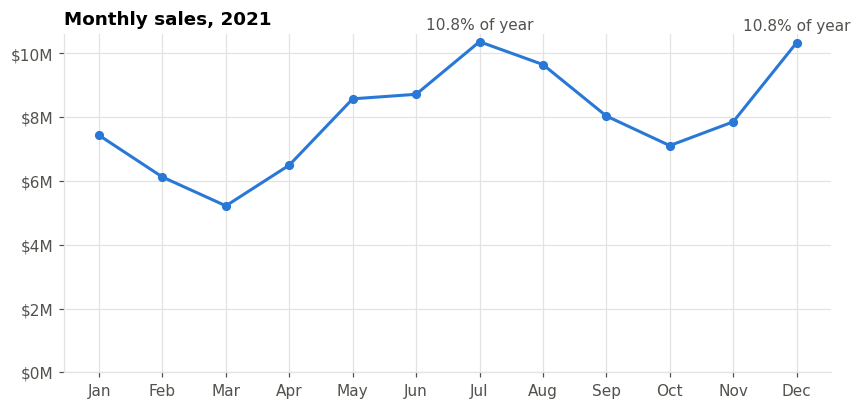

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
share of 2021 sales,7.7%,6.4%,5.4%,6.8%,8.9%,9.1%,10.8%,10.1%,8.4%,7.4%,8.2%,10.8%


In [10]:
monthly = d21.groupby("month").sales.sum()
share = monthly / monthly.sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index.strftime("%b"), monthly.values, color=BLUE, linewidth=2,
        marker="o", markersize=5)
ax.yaxis.set_major_formatter(millions)
ax.set_ylim(0)
ax.set_title("Monthly sales, 2021")
for m in ["Jul", "Dec"]:
    i = list(monthly.index.strftime("%b")).index(m)
    ax.annotate(f"{share.iloc[i]:.1%} of year", (i, monthly.iloc[i]),
                textcoords="offset points", xytext=(0, 8), ha="center", color=MUTED)
fig.savefig("figures/monthly_sales_2021.png")
plt.show()

share.rename(lambda p: p.strftime("%b")).to_frame("share of 2021 sales").T.style.format("{:.1%}")

Sales build through spring, peak in **July and December** (10.8% of the year each), and dip in
March, the weakest month at 5.4%.

## 5. Products

In [11]:
products = summary("product")
products

,sales,profit,units,share,margin,avg_price
product,,,,,,
Men's Street Footwear,"22,689,749.00","9,457,303.18",494134,0.24,0.42,45.92
Women's Apparel,"19,178,278.00","8,071,771.59",353619,0.20,0.42,54.23
Men's Athletic Footwear,"16,339,593.00","6,091,912.53",353766,0.17,0.37,46.19
Women's Street Footwear,"13,535,783.00","5,168,090.34",316478,0.14,0.38,42.77
Men's Apparel,"13,025,293.00","5,009,491.21",245456,0.14,0.38,53.07
Women's Athletic Footwear,"11,160,629.00","4,410,893.77",253059,0.12,0.40,44.10


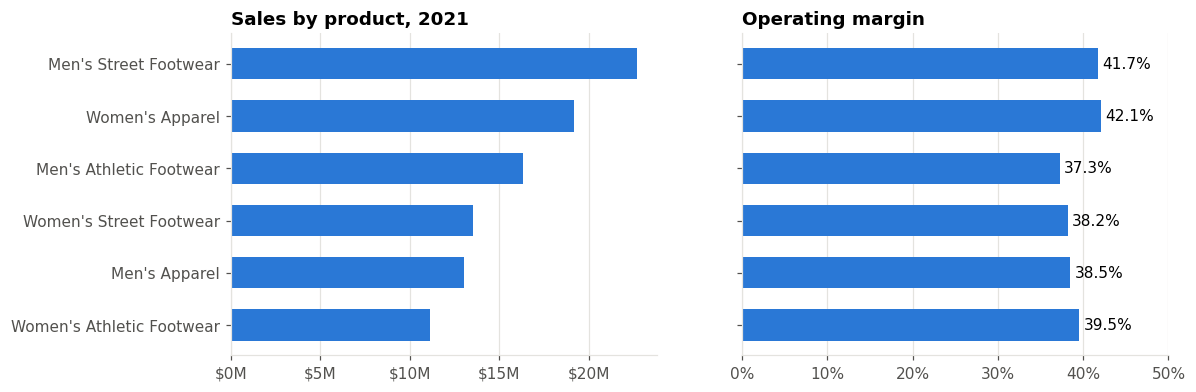

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = products.index[::-1]
axes[0].barh(order, products.loc[order, "sales"], color=BLUE, height=0.6)
axes[0].xaxis.set_major_formatter(millions)
axes[0].set_title("Sales by product, 2021")
axes[1].barh(order, products.loc[order, "margin"], color=BLUE, height=0.6)
axes[1].xaxis.set_major_formatter(pct)
axes[1].set_xlim(0, 0.5)
for i, v in enumerate(products.loc[order, "margin"]):
    axes[1].text(v + 0.005, i, f"{v:.1%}", va="center", color=INK)
axes[1].set_title("Operating margin")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.savefig("figures/products_2021.png")
plt.show()

**Men's street footwear is the biggest line** at 23.7% of sales, with a 41.7% margin. Women's
apparel is second at 20.0% but has both the highest margin (42.1%) and the highest average price
($54). Footwear as a whole is two-thirds of sales.

## 6. Retailers and sales channels

In [13]:
retailers = summary("retailer")
retailers

,sales,profit,units,share,margin,avg_price
retailer,,,,,,
Foot Locker,"23,276,065.00","9,093,400.44",484065,0.24,0.39,48.08
Sports Direct,"22,628,271.00","9,839,868.42",511374,0.24,0.43,44.25
West Gear,"20,705,942.00","8,102,887.20",431495,0.22,0.39,47.99
Kohl's,"13,419,950.00","5,143,256.41",285161,0.14,0.38,47.06
Amazon,"10,096,987.00","3,984,432.06",197990,0.11,0.39,51.00
Walmart,"5,802,110.00","2,045,618.09",106427,0.06,0.35,54.52


In [14]:
channels = summary("sales_method")
channels

,sales,profit,units,share,margin,avg_price
sales_method,,,,,,
Online,"40,445,691.00","17,436,051.48",852008,0.42,0.43,47.47
Outlet,"29,209,559.00","11,173,837.39",631089,0.30,0.38,46.28
In-store,"26,274,075.00","9,599,573.75",533415,0.27,0.37,49.26


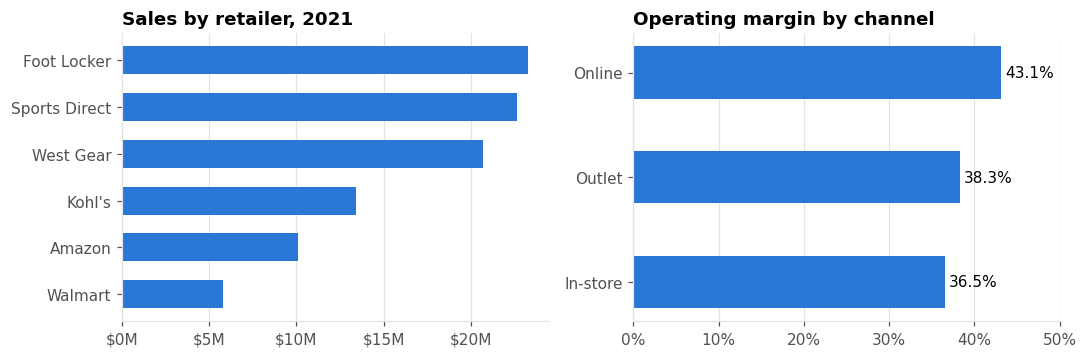

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
r = retailers.index[::-1]
axes[0].barh(r, retailers.loc[r, "sales"], color=BLUE, height=0.6)
axes[0].xaxis.set_major_formatter(millions)
axes[0].set_title("Sales by retailer, 2021")
c = channels.index[::-1]
axes[1].barh(c, channels.loc[c, "margin"], color=BLUE, height=0.5)
axes[1].xaxis.set_major_formatter(pct)
axes[1].set_xlim(0, 0.5)
for i, v in enumerate(channels.loc[c, "margin"]):
    axes[1].text(v + 0.005, i, f"{v:.1%}", va="center", color=INK)
axes[1].set_title("Operating margin by channel")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.savefig("figures/retailers_channels_2021.png")
plt.show()

- **Three retailers carry 70% of sales:** Foot Locker (24.3%), Sports Direct (23.6%) and West Gear
  (21.6%). Sports Direct earns the best margin of the six (43.5%); Walmart is smallest and has the
  lowest margin (35.3%).
- **Online is the largest and most profitable channel:** 42.2% of sales at a 43.1% margin, against
  36.5% for in-store. Selling a dollar online earns about 6.6 cents more operating profit than
  selling it in a store.

## 7. Regions and states

In [16]:
summary("region")

,sales,profit,units,share,margin,avg_price
region,,,,,,
West,"26,417,754.00","9,587,611.96",523942,0.28,0.36,50.42
Northeast,"19,267,008.00","7,568,663.34",386268,0.20,0.39,49.88
Southeast,"17,500,323.00","6,813,671.34",333865,0.18,0.39,52.42
South,"16,973,724.00","7,726,833.01",401938,0.18,0.46,42.23
Midwest,"15,770,516.00","6,512,682.97",370499,0.16,0.41,42.57


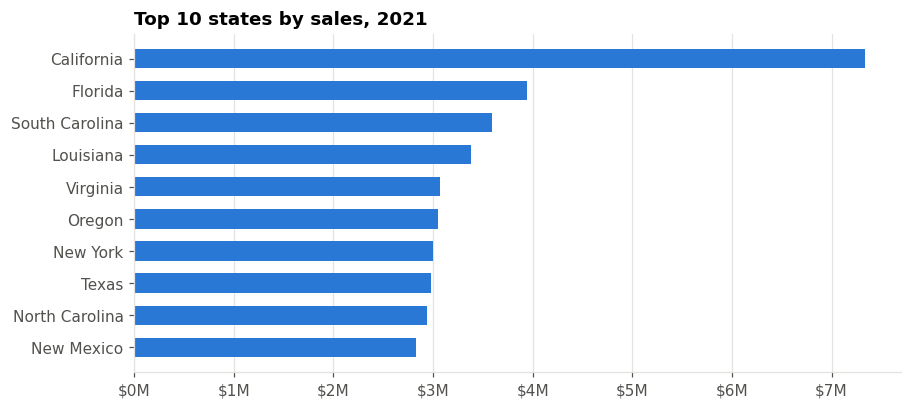

top 5 states: 22.2% of sales; California alone: 7.6%


In [17]:
states = summary("state")
top = states.head(10)

fig, ax = plt.subplots(figsize=(9, 4))
t = top.index[::-1]
ax.barh(t, top.loc[t, "sales"], color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(millions)
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 states by sales, 2021")
fig.savefig("figures/top_states_2021.png")
plt.show()

print(f"top 5 states: {states.head(5).share.sum():.1%} of sales; "
      f"California alone: {states.loc['California', 'share']:.1%}")

The **West is the largest region** (27.5% of sales) but has the lowest margin (36.3%). The **South
has the highest margin** (45.5%) despite the lowest average selling price, which suggests lower costs
there rather than higher prices. California is the biggest single state at 7.6% of sales.

## 8. Pricing by channel

Is the online margin advantage explained by higher online prices?

In [18]:
price = (d21.groupby(["product", "sales_method"])
         .apply(lambda g: g.sales.sum() / g.units_sold.sum(), include_groups=False)
         .unstack()[["In-store", "Online", "Outlet"]])
price.style.format("${:.2f}")

sales_method,In-store,Online,Outlet
product,,,
Men's Apparel,$55.28,$53.48,$50.55
Men's Athletic Footwear,$47.80,$46.02,$45.15
Men's Street Footwear,$48.82,$45.71,$43.42
Women's Apparel,$55.83,$54.37,$52.68
Women's Athletic Footwear,$44.47,$43.99,$43.96
Women's Street Footwear,$42.86,$42.15,$43.51


No. In-store prices are **higher** than online for every product, so online's better margin comes
from lower costs per sale, not from charging more. Outlet prices are below in-store for five of the
six products, by up to 11% for men's street footwear.

## 9. Summary of findings

1. **Data quality first:** 40% of records report sales at exactly 10x price x units. Uncorrected,
   this overstates sales 7.5-fold and makes in-store look like the biggest channel when it is the
   smallest.
2. **2021** (the only complete year): $95.9M sales and $38.2M operating profit, a 39.8% margin, on
   2.0 million units.
3. **Online leads** on both size (42% of sales) and margin (43.1% vs 36.5% in-store), and not
   because of higher prices: online prices are below in-store for every product.
4. **Men's street footwear** is the largest product line; **women's apparel** has the best margin
   and highest prices.
5. **Three retailers** (Foot Locker, Sports Direct, West Gear) account for 70% of sales.
6. **The South earns the best margin** at the lowest prices; the West sells the most at the lowest
   margin.
7. **Seasonality:** peaks in July and December, low in March.